# 07. Model Evaluation — Baseline vs Focal Loss

**Purpose:** evaluate the original BCE model and the Focal Loss experiment on the validation split using the same decoding and matching rules.

- Uses validation data only; the test split is deliberately not evaluated here.
- Reports detection Precision, Recall, F1, AP@0.50 and mAP@0.50:0.95.
- Detection metrics depend on confidence threshold, NMS IoU, and matching IoU. Keep these settings identical for a fair comparison.
- This notebook assumes model inputs are RGB images scaled to `[0,1]`, matching the current training pipeline. If Notebook 05/06 used a different preprocessing function, make `load_image()` match it exactly.

> **Preprocessing correction:** This notebook uses the exact MobileNetV2 `preprocess_input` transform used by Notebook 06 training. The earlier `/255.0` evaluation preprocessing did not match training and could suppress or distort predictions.

In [ ]:

import os, sys, json, math, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import confusion_matrix, classification_report
warnings.filterwarnings("ignore")

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), Path.cwd().parent]
     if (p / "src" / "data" / "dataset.py").exists()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Project root not found. Open this notebook from the project root or notebooks folder."
    )
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

DATASET_PATH = PROJECT_ROOT / "data" / "NEU-DET"
BASELINE_PATH = PROJECT_ROOT / "models" / "best_model.keras"
FOCAL_PATH = PROJECT_ROOT / "models" / "focal_experiment" / "best_model_focal.keras"
ANCHORS_PATH = PROJECT_ROOT / "models" / "anchors.npy"
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

CLASS_NAMES = [
    "crazing", "inclusion", "patches",
    "pitted_surface", "rolled-in_scale", "scratches"
]
NUM_CLASSES = len(CLASS_NAMES)
GRID_SIZE = 7
NUM_ANCHORS = 5
IMAGE_SIZE = 224

print("Project:", PROJECT_ROOT)
print("TensorFlow:", tf.__version__)



Project: d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow
TensorFlow: 2.15.0


In [ ]:

from src.data.dataset import get_dataset_splits

train_samples, val_samples, test_samples = get_dataset_splits(str(DATASET_PATH))
print(f"Train: {len(train_samples)} | Validation: {len(val_samples)} | Test: {len(test_samples)}")

if not ANCHORS_PATH.exists():
    raise FileNotFoundError(f"Missing anchors file: {ANCHORS_PATH}")
anchors = np.load(ANCHORS_PATH).astype(np.float32)
assert anchors.shape == (NUM_ANCHORS, 2), f"Expected anchors shape (5,2), got {anchors.shape}"
print("Anchors:\n", anchors)

def load_image(image_path):
    """
    IMPORTANT: Match Notebook 06 training preprocessing exactly.
    MobileNetV2 preprocess_input maps RGB pixel values from [0, 255] to [-1, 1].
    Do NOT divide by 255 here.
    """
    image = Image.open(image_path).convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE))
    image = np.asarray(image, dtype=np.float32)  # keep [0, 255] before preprocessing
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    return image.astype(np.float32)

def box_iou_xyxy(a, b):
    ax1, ay1, ax2, ay2 = map(float, a)
    bx1, by1, bx2, by2 = map(float, b)
    ix1, iy1 = max(ax1,bx1), max(ay1,by1)
    ix2, iy2 = min(ax2,bx2), min(ay2,by2)
    iw, ih = max(0.0,ix2-ix1), max(0.0,iy2-iy1)
    inter = iw*ih
    area_a = max(0.0,ax2-ax1)*max(0.0,ay2-ay1)
    area_b = max(0.0,bx2-bx1)*max(0.0,by2-by1)
    return inter / (area_a+area_b-inter+1e-9)

def decode_predictions(raw, anchors, conf_threshold=0.25, nms_iou=0.50, max_detections=100):
    raw = np.asarray(raw)
    if raw.ndim == 5:
        raw = raw[0]
    if raw.shape != (GRID_SIZE, GRID_SIZE, NUM_ANCHORS, 5+NUM_CLASSES):
        raise ValueError(f"Unexpected model output shape: {raw.shape}")
    detections = []
    for row in range(GRID_SIZE):
        for col in range(GRID_SIZE):
            for anchor_id in range(NUM_ANCHORS):
                pred = raw[row, col, anchor_id]
                tx, ty, tw, th = pred[:4]
                obj = 1.0 / (1.0 + np.exp(-np.clip(float(pred[4]), -30, 30)))
                cls_logits = pred[5:]
                cls_exp = np.exp(cls_logits - np.max(cls_logits))
                cls_probs = cls_exp / (np.sum(cls_exp) + 1e-9)
                class_id = int(np.argmax(cls_probs))
                score = float(obj * cls_probs[class_id])
                if score < conf_threshold:
                    continue

                # Training encoder stores tx/ty as direct within-cell offsets.
                tx = float(np.clip(tx, 0.0, 1.0))
                ty = float(np.clip(ty, 0.0, 1.0))
                cx = (col + tx) / GRID_SIZE
                cy = (row + ty) / GRID_SIZE
                w = float(anchors[anchor_id,0] * np.exp(np.clip(tw,-5,5)))
                h = float(anchors[anchor_id,1] * np.exp(np.clip(th,-5,5)))
                box = [
                    float(np.clip(cx-w/2,0,1)),
                    float(np.clip(cy-h/2,0,1)),
                    float(np.clip(cx+w/2,0,1)),
                    float(np.clip(cy+h/2,0,1))
                ]
                if box[2] > box[0] and box[3] > box[1]:
                    detections.append({"box":box, "score":score, "class_id":class_id})

    # Class-wise greedy NMS
    kept = []
    for class_id in range(NUM_CLASSES):
        class_dets = sorted(
            [d for d in detections if d["class_id"] == class_id],
            key=lambda x: x["score"], reverse=True
        )
        class_kept = []
        while class_dets:
            best = class_dets.pop(0)
            class_kept.append(best)
            class_dets = [
                d for d in class_dets
                if box_iou_xyxy(best["box"], d["box"]) < nms_iou
            ]
        kept.extend(class_kept)
    kept = sorted(kept, key=lambda x:x["score"], reverse=True)
    return kept[:max_detections]

def get_ground_truth(sample):
    boxes = np.asarray(sample["boxes"], dtype=np.float32).reshape(-1,4)
    labels = np.asarray(sample["labels"], dtype=np.int32).reshape(-1)
    return boxes, labels

def load_model_if_present(path):
    if not path.exists():
        print(f"SKIP - checkpoint not found: {path}")
        return None
    model = tf.keras.models.load_model(path, compile=False)
    print(f"Loaded: {path.name}; output shape: {model.output_shape}")
    return model

def predict_sample(model, sample):
    x = load_image(sample["image"])[None, ...]
    raw = model.predict(x, verbose=0)
    return raw


Train: 1151 | Validation: 288 | Test: 360
Anchors:
 [[0.1828321  0.24619976]
 [0.28540698 0.51598006]
 [0.21671906 0.910609  ]
 [0.6913246  0.32715988]
 [0.81677145 0.9229429 ]]


## 1. Evaluation settings

In [ ]:

CONF_THRESHOLD = 0.25
NMS_IOU = 0.50
MATCH_IOU = 0.50
AP_IOU_THRESHOLDS = np.arange(0.50, 0.96, 0.05)
MAX_DETECTIONS = 100

models = {
    "Baseline_BCE": load_model_if_present(BASELINE_PATH),
    "Focal_Loss": load_model_if_present(FOCAL_PATH),
}
models = {name:model for name,model in models.items() if model is not None}
if not models:
    raise FileNotFoundError("No model checkpoints found. Train the baseline and/or Focal Loss model first.")
print("Models to evaluate:", list(models))




Loaded: best_model.keras; output shape: (None, 7, 7, 5, 11)
Loaded: best_model_focal.keras; output shape: (None, 7, 7, 5, 11)
Models to evaluate: ['Baseline_BCE', 'Focal_Loss']


## 2. Run predictions on validation set

In [ ]:

# Store detections by model and image index.
all_predictions = {}
for model_name, model in models.items():
    print(f"\nEvaluating predictions: {model_name}")
    model_predictions = []
    for idx, sample in enumerate(val_samples):
        raw = predict_sample(model, sample)
        dets = decode_predictions(
            raw, anchors,
            conf_threshold=CONF_THRESHOLD,
            nms_iou=NMS_IOU,
            max_detections=MAX_DETECTIONS
        )
        model_predictions.append(dets)
        if (idx+1) % 50 == 0 or idx+1 == len(val_samples):
            print(f"  {idx+1}/{len(val_samples)}")
    all_predictions[model_name] = model_predictions



Evaluating predictions: Baseline_BCE
  50/288
  100/288
  150/288
  200/288
  250/288
  288/288

Evaluating predictions: Focal_Loss
  50/288
  100/288
  150/288
  200/288
  250/288
  288/288


## 3. Detection matching and metrics

In [ ]:

def match_detections(predictions, samples, iou_threshold=0.50):
    # Greedy score-ordered matching, separately by class and image.
    tp = fp = fn = 0
    y_true_cls, y_pred_cls = [], []
    per_class = {c: {"tp":0,"fp":0,"fn":0} for c in range(NUM_CLASSES)}

    for sample, dets in zip(samples, predictions):
        gt_boxes, gt_labels = get_ground_truth(sample)
        used = set()
        for det in sorted(dets, key=lambda d:d["score"], reverse=True):
            candidates = [
                (j, box_iou_xyxy(det["box"], gt_boxes[j]))
                for j in range(len(gt_boxes))
                if j not in used and int(gt_labels[j]) == det["class_id"]
            ]
            best = max(candidates, key=lambda x:x[1], default=(-1,0.0))
            c = det["class_id"]
            if best[0] >= 0 and best[1] >= iou_threshold:
                tp += 1; per_class[c]["tp"] += 1; used.add(best[0])
                y_true_cls.append(c); y_pred_cls.append(c)
            else:
                fp += 1; per_class[c]["fp"] += 1
        for j, c in enumerate(gt_labels):
            if j not in used:
                fn += 1; per_class[int(c)]["fn"] += 1

    precision = tp/(tp+fp+1e-9)
    recall = tp/(tp+fn+1e-9)
    f1 = 2*precision*recall/(precision+recall+1e-9)
    rows=[]
    for c, vals in per_class.items():
        p=vals["tp"]/(vals["tp"]+vals["fp"]+1e-9)
        r=vals["tp"]/(vals["tp"]+vals["fn"]+1e-9)
        f=2*p*r/(p+r+1e-9)
        rows.append({"class":CLASS_NAMES[c], **vals, "precision":p, "recall":r, "f1":f})
    return {"TP":tp,"FP":fp,"FN":fn,"precision":precision,"recall":recall,"f1":f1}, pd.DataFrame(rows)

def average_precision_for_class(predictions, samples, class_id, iou_threshold):
    # AP uses confidence-ranked detections across the complete validation split.
    total_gt = sum(int(np.sum(np.asarray(s["labels"]) == class_id)) for s in samples)
    if total_gt == 0:
        return np.nan
    ranked=[]
    for image_idx, dets in enumerate(predictions):
        for det in dets:
            if det["class_id"] == class_id:
                ranked.append((det["score"], image_idx, det["box"]))
    ranked.sort(key=lambda x:x[0], reverse=True)
    matched = [set() for _ in samples]
    tp_flags=[]; fp_flags=[]
    gt_cache=[get_ground_truth(s) for s in samples]
    for score, image_idx, box in ranked:
        gt_boxes, gt_labels = gt_cache[image_idx]
        candidates=[
            (j,box_iou_xyxy(box,gt_boxes[j]))
            for j in range(len(gt_boxes))
            if int(gt_labels[j])==class_id and j not in matched[image_idx]
        ]
        best=max(candidates,key=lambda x:x[1],default=(-1,0.0))
        if best[0]>=0 and best[1]>=iou_threshold:
            matched[image_idx].add(best[0]); tp_flags.append(1); fp_flags.append(0)
        else:
            tp_flags.append(0); fp_flags.append(1)
    if not tp_flags:
        return 0.0
    tp_cum=np.cumsum(tp_flags); fp_cum=np.cumsum(fp_flags)
    recalls=tp_cum/total_gt
    precisions=tp_cum/(tp_cum+fp_cum+1e-9)
    # 101-point interpolated AP
    return float(np.mean([
        np.max(precisions[recalls>=r]) if np.any(recalls>=r) else 0.0
        for r in np.linspace(0,1,101)
    ]))

def calculate_map(predictions, samples):
    rows=[]
    for threshold in AP_IOU_THRESHOLDS:
        aps=[average_precision_for_class(predictions,samples,c,threshold) for c in range(NUM_CLASSES)]
        rows.append({"IoU":round(float(threshold),2),"mAP":float(np.nanmean(aps))})
    return pd.DataFrame(rows)


## 4. Evaluate and compare

In [ ]:

summary_rows=[]
class_results={}
map_results={}
for name, preds in all_predictions.items():
    overall, per_class = match_detections(preds, val_samples, MATCH_IOU)
    map_df = calculate_map(preds, val_samples)
    summary_rows.append({
        "model":name, **overall,
        "mAP@0.50":float(map_df.loc[map_df["IoU"]==0.5,"mAP"].iloc[0]),
        "mAP@0.50:0.95":float(map_df["mAP"].mean())
    })
    class_results[name]=per_class
    map_results[name]=map_df

summary_df=pd.DataFrame(summary_rows)
display(summary_df.round(4))
for name, df in class_results.items():
    print("\\nPer-class metrics:",name)
    display(df.round(4))


,model,TP,FP,FN,precision,recall,f1,mAP@0.50,mAP@0.50:0.95
0,Baseline_BCE,414,15853,242,0.0255,0.6311,0.0489,0.1582,0.0458
1,Focal_Loss,407,8301,249,0.0467,0.6204,0.0869,0.2064,0.0672


\nPer-class metrics: Baseline_BCE


,class,tp,fp,fn,precision,recall,f1
0,crazing,90,2401,15,0.0361,0.8571,0.0693
1,inclusion,59,4212,102,0.0138,0.3665,0.0266
2,patches,90,3635,41,0.0242,0.6870,0.0467
3,pitted_surface,60,660,18,0.0833,0.7692,0.1504
4,rolled-in_scale,67,3413,30,0.0193,0.6907,0.0375
5,scratches,48,1532,36,0.0304,0.5714,0.0577


\nPer-class metrics: Focal_Loss


,class,tp,fp,fn,precision,recall,f1
0,crazing,88,1259,17,0.0653,0.8381,0.1212
1,inclusion,63,1982,98,0.0308,0.3913,0.0571
2,patches,90,1956,41,0.0440,0.6870,0.0827
3,pitted_surface,61,259,17,0.1906,0.7821,0.3065
4,rolled-in_scale,62,2106,35,0.0286,0.6392,0.0547
5,scratches,43,739,41,0.0550,0.5119,0.0993


## 5. Plot mAP across IoU thresholds

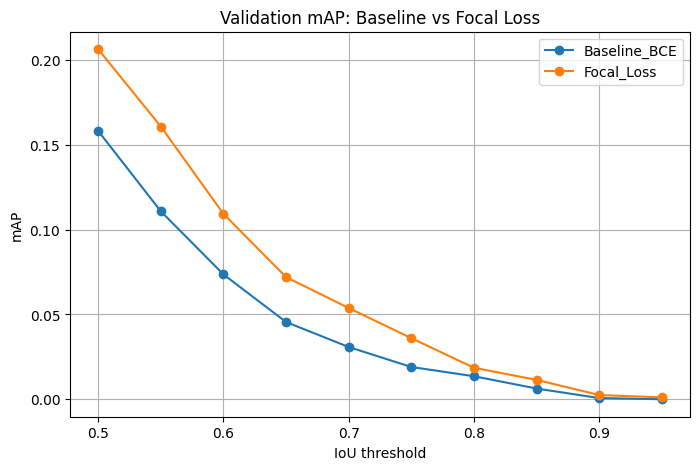

In [ ]:

plt.figure(figsize=(8,5))
for name, df in map_results.items():
    plt.plot(df["IoU"], df["mAP"], marker="o", label=name)
plt.xlabel("IoU threshold"); plt.ylabel("mAP")
plt.title("Validation mAP: Baseline vs Focal Loss")
plt.grid(True); plt.legend(); plt.show()


## 6. Save results

In [ ]:

summary_path=RESULTS_DIR/"model_comparison_validation.csv"
summary_df.to_csv(summary_path,index=False)
for name, df in class_results.items():
    df.to_csv(RESULTS_DIR/f"{name.lower()}_per_class_validation.csv",index=False)
for name, df in map_results.items():
    df.to_csv(RESULTS_DIR/f"{name.lower()}_map_validation.csv",index=False)
print("Saved evaluation results to:", RESULTS_DIR)
print("Comparison:", summary_path)


Saved evaluation results to: d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow\results
Comparison: d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow\results\model_comparison_validation.csv


## Interpretation notes

- Precision measures how many predicted detections were correct; recall measures how many ground-truth objects were found.
- F1 balances precision and recall.
- AP is calculated per class from confidence-ranked detections; mAP averages AP across the six classes.
- A high training/validation loss improvement does **not** prove better detection. Use these detection metrics and visual inspection.
- This implementation uses greedy class-aware matching and 101-point interpolated AP. For publication-grade benchmarking, cross-check with a standard COCO/VOC evaluation implementation.
- Do not select a confidence threshold by repeatedly tuning on the test set. Tune on validation, freeze settings, then evaluate test once.